# YES BANK Stock Price Prediction

## Exploratory Data Analysis (EDA)

**Project Objective:** To analyse historical YES BANK stock prices, identify trends and patterns, understand relationships among stock price variables, and derive meaningful insights that support stock price prediction.

### Business Objective

The business objective of this project is to understand YES BANK's historical stock performance, identify patterns in price movements and volatility, and use these insights to support data-driven financial analysis. This analysis can help investors and analysts better understand historical market behaviour, although it cannot guarantee future stock prices.

In [1]:
# Import essential libraries for data analysis

import pandas as pd
import numpy as np

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style('whitegrid')

# Display all columns in DataFrame
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Upload the dataset

from google.colab import files
uploaded = files.upload()

Saving data_YesBank_StockPrices.csv to data_YesBank_StockPrices (2).csv


In [3]:
# Load the dataset into a DataFrame

df = pd.read_csv('data_YesBank_StockPrices.csv')

# Display the first five rows
df.head()

,Date,Open,High,Low,Close
0,Jul-05,13.00,14.00,11.25,12.46
1,Aug-05,12.58,14.88,12.55,13.42
2,Sep-05,13.48,14.87,12.27,13.30
3,Oct-05,13.20,14.47,12.40,12.99
4,Nov-05,13.35,13.88,12.88,13.41


In [4]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (185, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    object 
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), object(1)
memory usage: 7.4+ KB

Statistical Summary:


,Open,High,Low,Close
count,185.000000,185.000000,185.000000,185.000000
mean,105.541405,116.104324,94.947838,105.204703
std,98.879850,106.333497,91.219415,98.583153
min,10.000000,11.240000,5.550000,9.980000
25%,33.800000,36.140000,28.510000,33.450000
50%,62.980000,72.550000,58.000000,62.540000
75%,153.000000,169.190000,138.350000,153.300000
max,369.950000,404.000000,345.500000,367.900000


In [5]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

# Check data types
print("\nColumn Data Types:")
print(df.dtypes)

# Check dataset dimensions
print("\nDataset Shape:", df.shape)

Missing Values:
Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64

Number of Duplicate Rows:
0

Column Data Types:
Date      object
Open     float64
High     float64
Low      float64
Close    float64
dtype: object

Dataset Shape: (185, 5)


In [6]:
# Validate OHLC price relationships

print("OHLC Data Validation")

print("High price below Open or Close:",
      ((df['High'] < df[['Open', 'Close']].max(axis=1))).sum())

print("Low price above Open or Close:",
      ((df['Low'] > df[['Open', 'Close']].min(axis=1))).sum())

print("High price below Low price:",
      (df['High'] < df['Low']).sum())

print("Duplicate dates:", df['Date'].duplicated().sum())

OHLC Data Validation
High price below Open or Close: 0
Low price above Open or Close: 0
High price below Low price: 0
Duplicate dates: 0


In [7]:
# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'], format='%b-%y')

# Sort the dataset chronologically
df = df.sort_values(by='Date').reset_index(drop=True)

# Verify the conversion
print("Updated Data Types:")
print(df.dtypes)

# Display first five records
display(df.head())

Updated Data Types:
Date     datetime64[ns]
Open            float64
High            float64
Low             float64
Close           float64
dtype: object


,Date,Open,High,Low,Close
0,2005-07-01,13.00,14.00,11.25,12.46
1,2005-08-01,12.58,14.88,12.55,13.42
2,2005-09-01,13.48,14.87,12.27,13.30
3,2005-10-01,13.20,14.47,12.40,12.99
4,2005-11-01,13.35,13.88,12.88,13.41


In [8]:
# Feature Engineering

# 1. Monthly price change
df['Price_Change'] = df['Close'] - df['Open']

# 2. Monthly percentage return
df['Monthly_Return'] = df['Close'].pct_change() * 100

# 3. Monthly price range
df['Price_Range'] = df['High'] - df['Low']

# 4. 3-month moving average of closing price
df['MA_3'] = df['Close'].rolling(window=3).mean()

# Display the updated dataset
display(df.head(10))

,Date,Open,High,Low,Close,Price_Change,Monthly_Return,Price_Range,MA_3
0,2005-07-01,13.00,14.00,11.25,12.46,-0.54,NaN,2.75,NaN
1,2005-08-01,12.58,14.88,12.55,13.42,0.84,7.704655,2.33,NaN
2,2005-09-01,13.48,14.87,12.27,13.30,-0.18,-0.894188,2.60,13.060000
3,2005-10-01,13.20,14.47,12.40,12.99,-0.21,-2.330827,2.07,13.236667
4,2005-11-01,13.35,13.88,12.88,13.41,0.06,3.233256,1.00,13.233333
5,2005-12-01,13.49,14.44,13.00,13.71,0.22,2.237136,1.44,13.370000
6,2006-01-01,13.68,17.16,13.58,15.33,1.65,11.816193,3.58,14.150000
7,2006-02-01,15.50,16.97,15.40,16.12,0.62,5.153294,1.57,15.053333
8,2006-03-01,16.20,20.95,16.02,20.08,3.88,24.565757,4.93,17.176667
9,2006-04-01,20.56,20.80,18.02,19.49,-1.07,-2.938247,2.78,18.563333


In [9]:
# Statistical summary of engineered features

display(
    df[['Price_Change', 'Monthly_Return',
        'Price_Range', 'MA_3']].describe()
)

,Price_Change,Monthly_Return,Price_Range,MA_3
count,185.000000,184.000000,185.000000,183.000000
mean,-0.336703,1.496974,21.156486,106.208579
std,20.725837,16.534288,23.452871,97.662344
min,-163.750000,-53.320312,1.000000,10.826667
25%,-4.140000,-5.608482,7.100000,33.123333
50%,0.550000,2.195954,13.450000,64.083333
75%,5.440000,8.447706,25.830000,154.851667
max,68.920000,69.963812,183.850000,354.370000


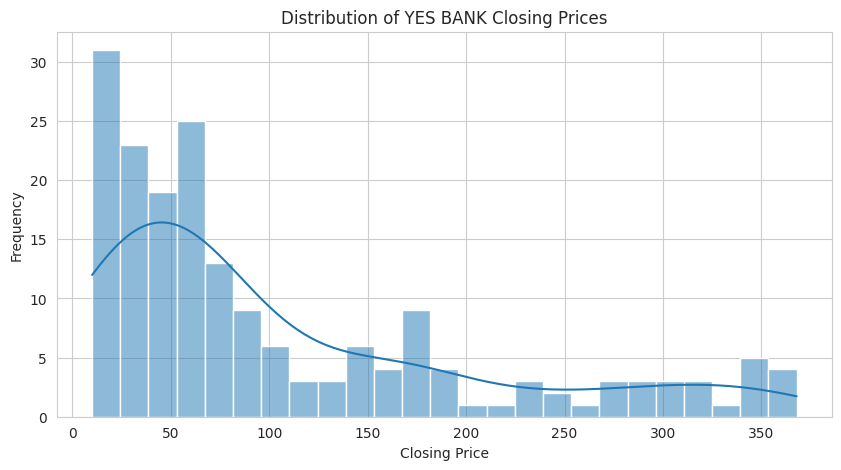

In [10]:
# Chart 1: Distribution of Closing Price

plt.figure(figsize=(10, 5))

sns.histplot(df['Close'], bins=25, kde=True)

plt.title('Distribution of YES BANK Closing Prices')
plt.xlabel('Closing Price')
plt.ylabel('Frequency')

plt.show()

**Purpose:** To understand the distribution and frequency of YES BANK's historical closing prices.

**Observation:** The distribution is positively skewed (right-skewed). Most closing prices are concentrated at lower values, while a few observations extend towards significantly higher prices.

**Business Impact:** This uneven distribution indicates substantial changes in historical stock price levels. Understanding the distribution helps in selecting and evaluating suitable prediction models.

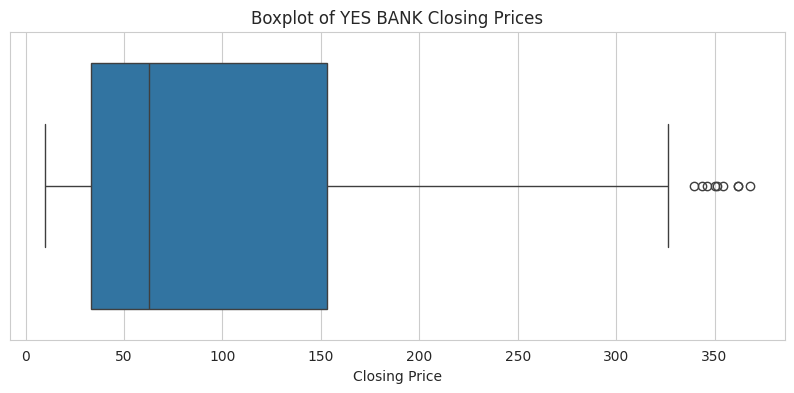

In [11]:
# Chart 2: Boxplot of YES BANK Closing Prices

plt.figure(figsize=(10, 4))

sns.boxplot(x=df['Close'])

plt.title('Boxplot of YES BANK Closing Prices')
plt.xlabel('Closing Price')

plt.show()

**Purpose:** To identify the spread of closing prices and detect potential outliers.

**Observation:** The boxplot shows a wide variation in closing prices, with several observations appearing beyond the upper whisker. These represent unusually high price values compared with the majority of observations.

**Business Impact:** Identifying extreme values is important because large price variations can influence statistical analysis and machine learning model performance.

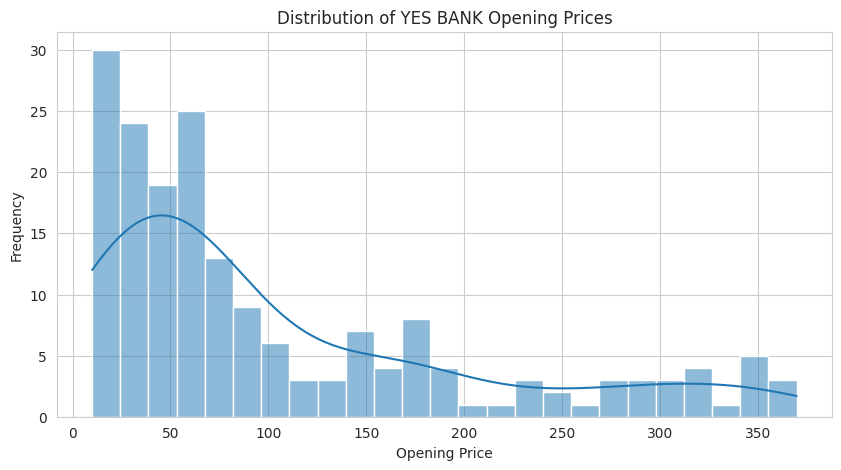

In [12]:
# Chart 3: Distribution of Opening Prices

plt.figure(figsize=(10, 5))

sns.histplot(df['Open'], bins=25, kde=True)

plt.title('Distribution of YES BANK Opening Prices')
plt.xlabel('Opening Price')
plt.ylabel('Frequency')

plt.show()

**Purpose:** To examine the distribution and frequency of YES BANK's opening prices.

**Observation:** The opening price distribution is positively skewed, with most observations concentrated in the lower price ranges and fewer observations at higher price levels.

**Business Impact:** Understanding opening price distribution helps identify changes in the stock's historical price levels and provides useful information for further analysis.

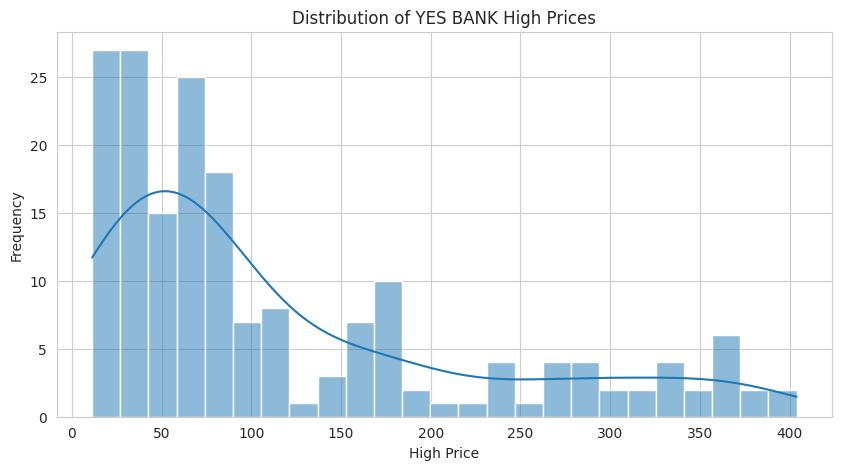

In [13]:
# Chart 4: Distribution of High Prices

plt.figure(figsize=(10, 5))

sns.histplot(df['High'], bins=25, kde=True)

plt.title('Distribution of YES BANK High Prices')
plt.xlabel('High Price')
plt.ylabel('Frequency')

plt.show()

**Purpose:** To understand the distribution of the highest prices recorded during each month.

**Observation:** The distribution is right-skewed, indicating that most monthly high prices fall within lower price ranges, while a smaller number of observations reach considerably higher levels.

**Business Impact:** This highlights the variation in the stock's monthly upper price levels and helps understand its historical price behaviour.

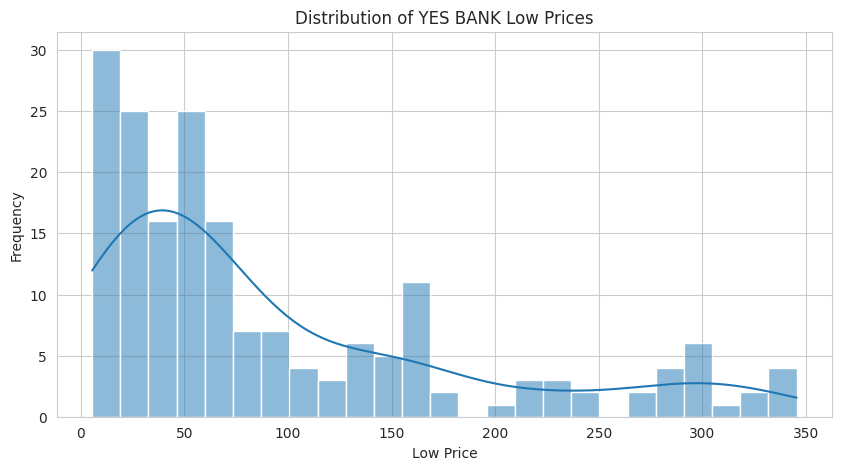

In [14]:
# Chart 5: Distribution of Low Prices

plt.figure(figsize=(10, 5))

sns.histplot(df['Low'], bins=25, kde=True)

plt.title('Distribution of YES BANK Low Prices')
plt.xlabel('Low Price')
plt.ylabel('Frequency')

plt.show()

**Purpose:** To examine the distribution of the lowest prices recorded during each month.

**Observation:** The distribution shows a concentration of observations at lower price levels, with fewer observations extending towards higher values.

**Business Impact:** Understanding monthly low prices helps assess historical downside price movements and provides useful information about the stock's price fluctuations.

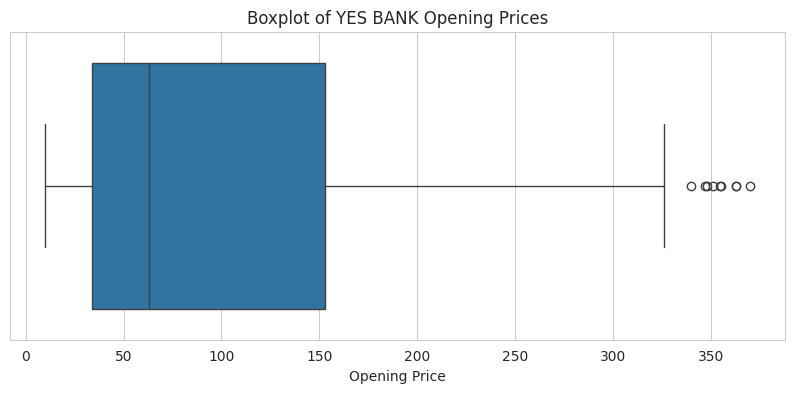

In [15]:
# Chart 6: Boxplot of Opening Prices

plt.figure(figsize=(10, 4))

sns.boxplot(x=df['Open'])

plt.title('Boxplot of YES BANK Opening Prices')
plt.xlabel('Opening Price')

plt.show()

**Purpose:** To identify the spread and potential outliers in monthly opening prices.

**Observation:** The boxplot indicates variation in opening prices, with some observations appearing considerably higher than the central range.

**Business Impact:** These extreme observations may represent important historical market movements. Identifying them helps avoid overlooking unusual price behaviour during analysis.

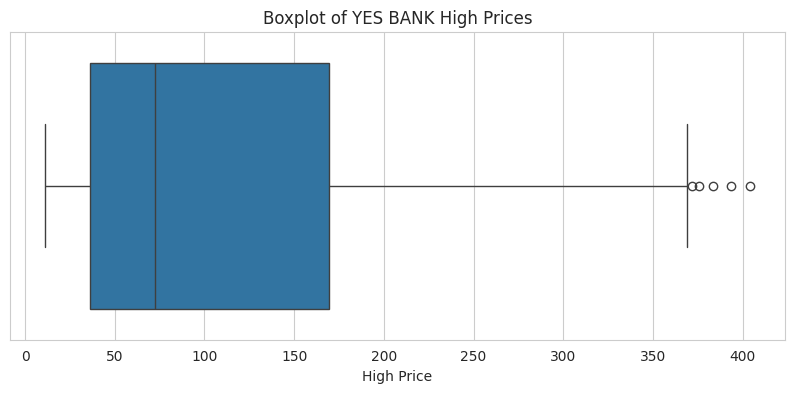

In [16]:
# Chart 7: Boxplot of High Prices

plt.figure(figsize=(10, 4))

sns.boxplot(x=df['High'])

plt.title('Boxplot of YES BANK High Prices')
plt.xlabel('High Price')

plt.show()

**Purpose:** To examine the spread of monthly high prices and identify extreme observations.

**Observation:** The boxplot shows a wide range of high prices and observations beyond the upper whisker, indicating unusually high monthly price levels.

**Business Impact:** Understanding these extreme price movements helps assess historical market fluctuations and their possible influence on prediction models.

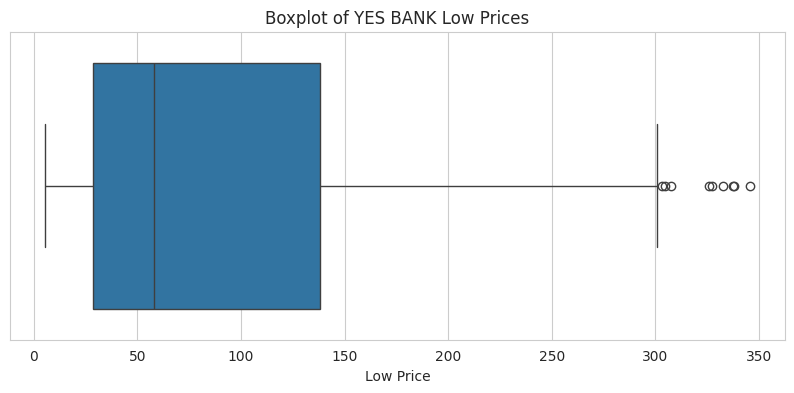

In [17]:
# Chart 8: Boxplot of Low Prices

plt.figure(figsize=(10, 4))

sns.boxplot(x=df['Low'])

plt.title('Boxplot of YES BANK Low Prices')
plt.xlabel('Low Price')

plt.show()

**Purpose:** To analyse the spread of monthly low prices and identify potential outliers.

**Observation:** The boxplot highlights variations in monthly low prices, including observations that extend beyond the main distribution.

**Business Impact:** This analysis helps identify unusual downside price levels and improves understanding of the stock's historical price behaviour.

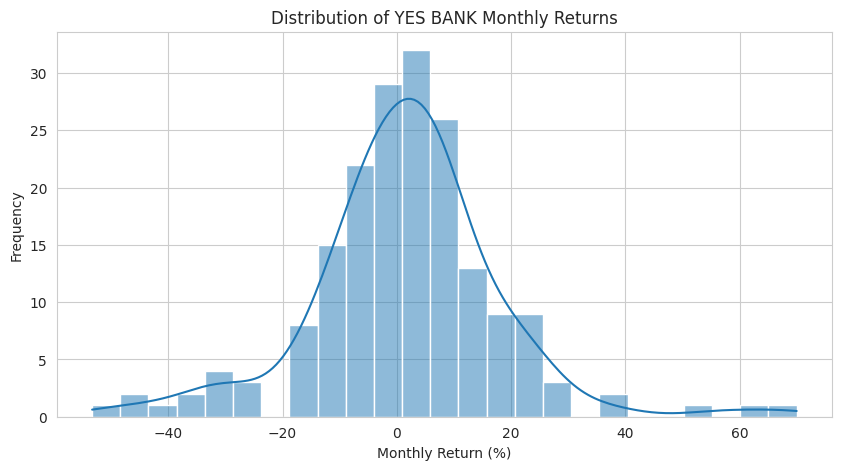

In [18]:
# Chart 9: Distribution of Monthly Returns

plt.figure(figsize=(10, 5))

sns.histplot(df['Monthly_Return'].dropna(), bins=25, kde=True)

plt.title('Distribution of YES BANK Monthly Returns')
plt.xlabel('Monthly Return (%)')
plt.ylabel('Frequency')

plt.show()

**Purpose:** To understand the distribution of monthly percentage returns and examine the frequency of gains and losses.

**Observation:** Monthly returns show variations on both the positive and negative sides, including extreme movements. The distribution indicates that monthly stock performance was not consistent.

**Business Impact:** Understanding return distribution helps assess the uncertainty and risk associated with the stock and highlights the importance of evaluating prediction errors carefully.

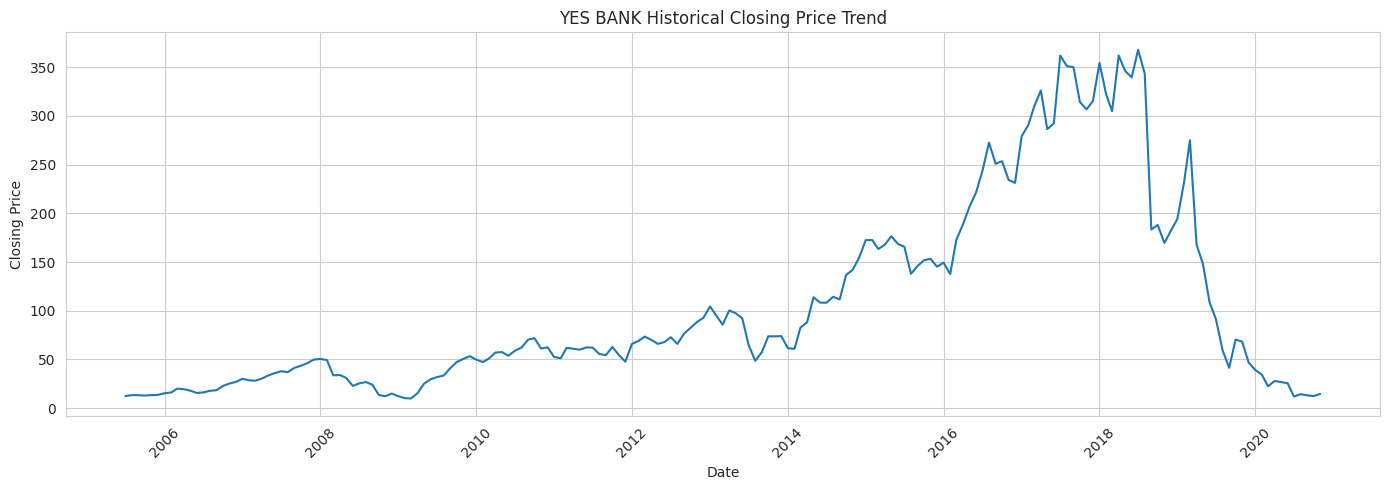

In [19]:
# Chart 10: Historical Closing Price Trend

plt.figure(figsize=(14, 5))

plt.plot(df['Date'], df['Close'])

plt.title('YES BANK Historical Closing Price Trend')
plt.xlabel('Date')
plt.ylabel('Closing Price')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Purpose:** To examine how YES BANK's closing price changed over the entire observation period.

**Observation:** The historical trend shows considerable price fluctuations, including periods of increase and decline. The maximum closing price was ₹367.90 in July 2018, while the minimum was ₹9.98 in March 2009.

**Business Impact:** Identifying historical price trends helps understand long-term market behaviour and provides a foundation for developing time-based prediction models.

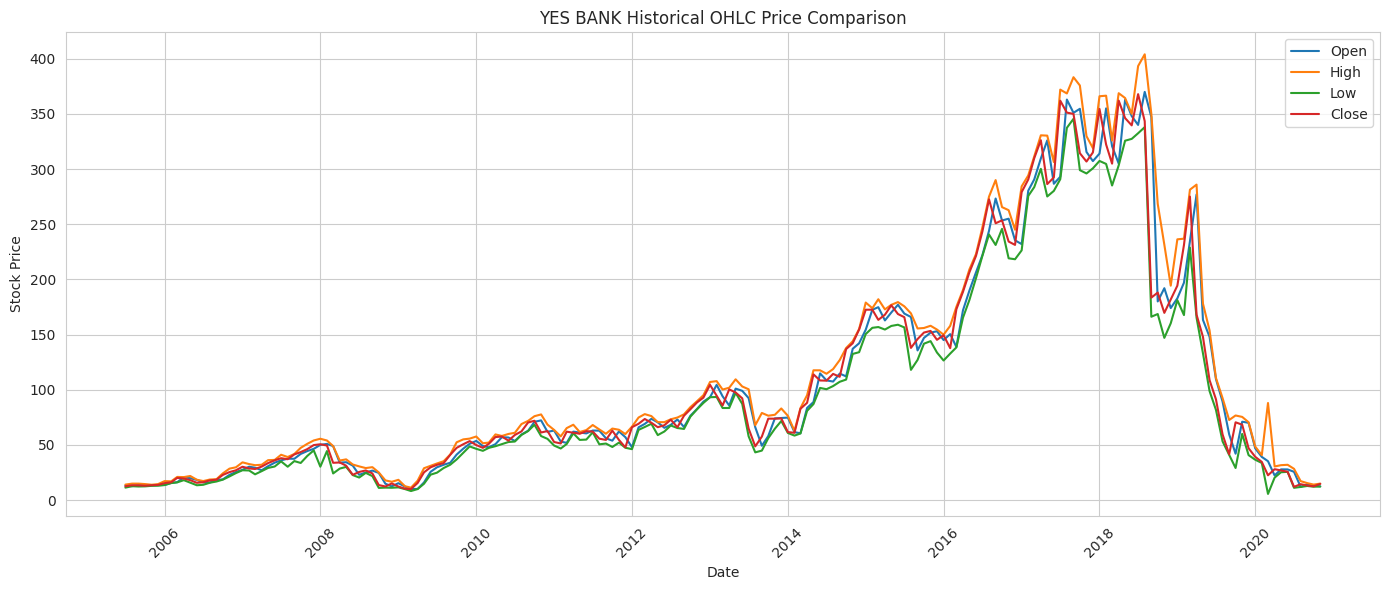

In [20]:
# Chart 11: Historical OHLC Price Comparison

plt.figure(figsize=(14, 6))

for column in ['Open', 'High', 'Low', 'Close']:
    plt.plot(df['Date'], df[column], label=column)

plt.title('YES BANK Historical OHLC Price Comparison')
plt.xlabel('Date')
plt.ylabel('Stock Price')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Purpose:** To compare the historical movements of opening, high, low and closing prices.

**Observation:** All four price variables follow similar overall movements over time. The high prices generally remain above the opening and closing prices, while the low prices remain below them.

**Business Impact:** Comparing OHLC values helps understand monthly price movements and provides multiple historical features that can support stock price prediction.

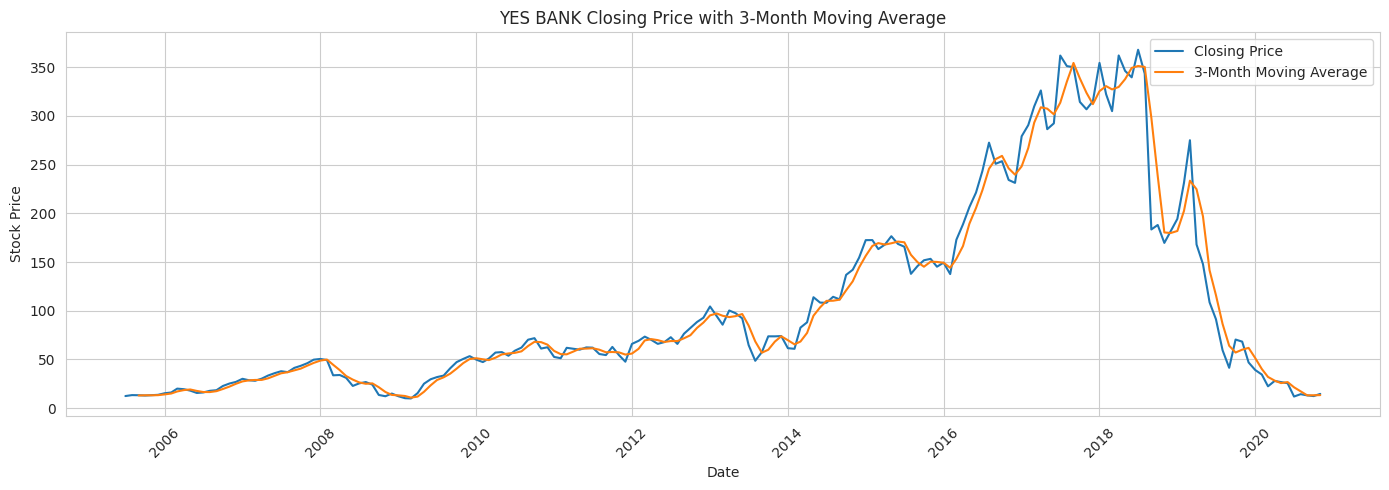

In [21]:
# Chart 12: Closing Price and 3-Month Moving Average

plt.figure(figsize=(14, 5))

plt.plot(df['Date'], df['Close'], label='Closing Price')
plt.plot(df['Date'], df['MA_3'], label='3-Month Moving Average')

plt.title('YES BANK Closing Price with 3-Month Moving Average')
plt.xlabel('Date')
plt.ylabel('Stock Price')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Purpose:** To compare actual closing prices with their 3-month moving average and identify underlying trends.

**Observation:** The moving average smooths short-term price fluctuations and makes broader upward and downward movements easier to identify. It follows the general direction of the closing price with some delay.

**Business Impact:** Moving averages help identify underlying price trends and can be used as useful features for understanding historical stock movements.

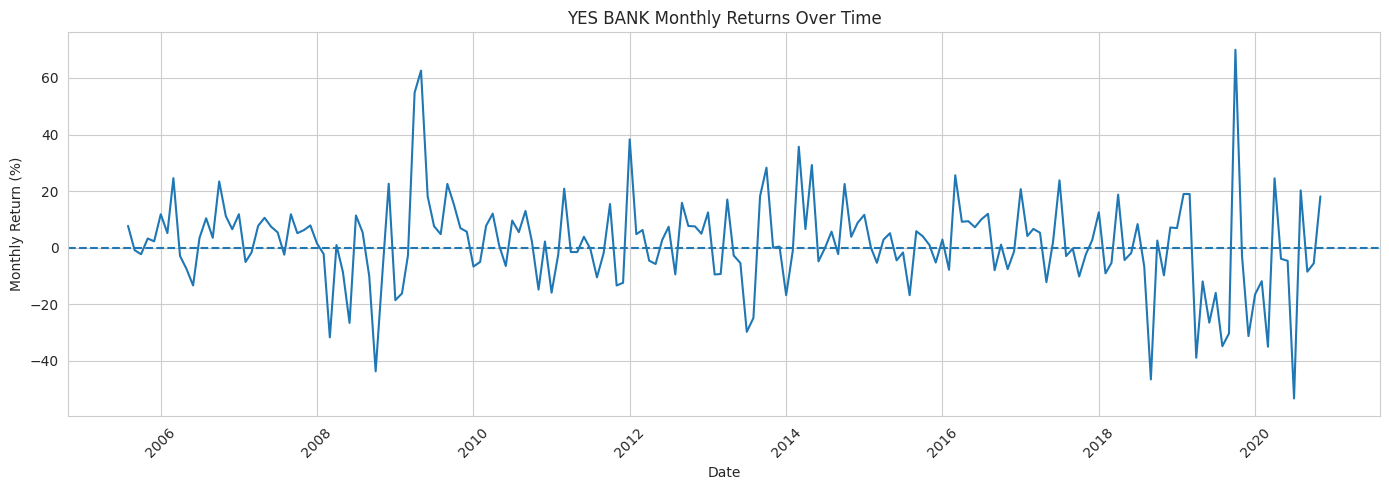

In [22]:
# Chart 13: Monthly Returns Over Time

plt.figure(figsize=(14, 5))

plt.plot(df['Date'], df['Monthly_Return'])
plt.axhline(y=0, linestyle='--')

plt.title('YES BANK Monthly Returns Over Time')
plt.xlabel('Date')
plt.ylabel('Monthly Return (%)')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Purpose:** To analyse how monthly percentage returns changed throughout the observation period.

**Observation:** Monthly returns fluctuate above and below the zero line, indicating alternating positive and negative monthly performance. Some periods show particularly large movements.

**Business Impact:** This analysis helps identify periods of significant gains and losses and highlights the importance of accounting for changing market conditions when predicting stock prices.

In [23]:
# Calculate 3-month rolling volatility

df['Rolling_Volatility'] = df['Monthly_Return'].rolling(window=3).std()

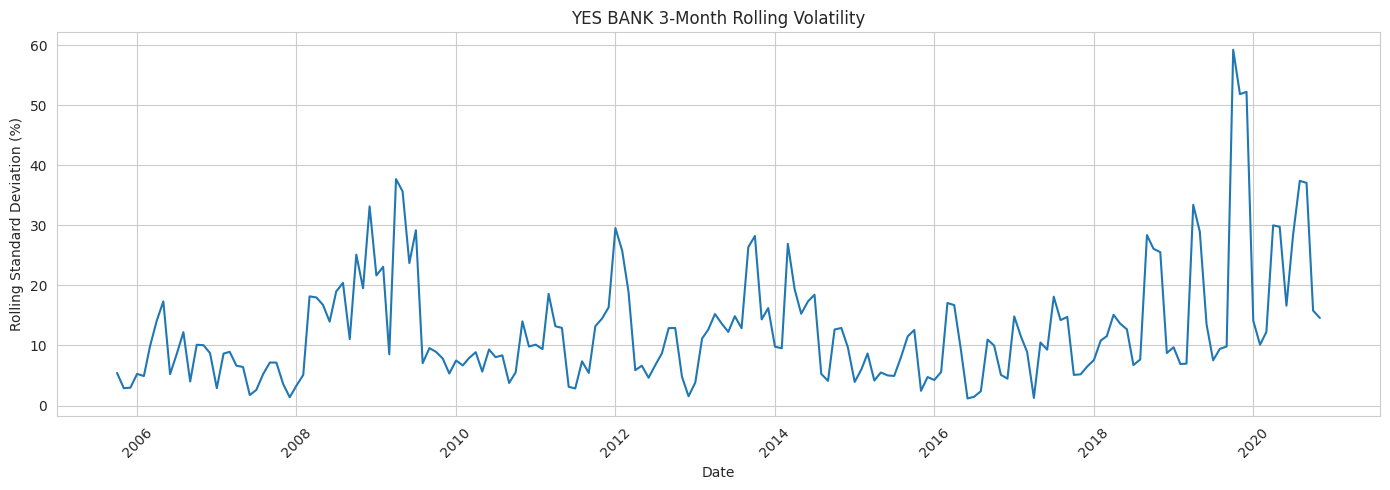

In [24]:
# Chart 14: Rolling Volatility

plt.figure(figsize=(14, 5))

plt.plot(df['Date'], df['Rolling_Volatility'])

plt.title('YES BANK 3-Month Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Rolling Standard Deviation (%)')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Purpose:** To examine changes in short-term stock return volatility using a 3-month rolling standard deviation.

**Observation:** Rolling volatility changes over time, with higher values representing periods of greater variation in monthly returns and lower values representing relatively stable periods.

**Business Impact:** Identifying periods of high volatility helps understand market uncertainty and the challenges involved in predicting stock prices during unstable periods.

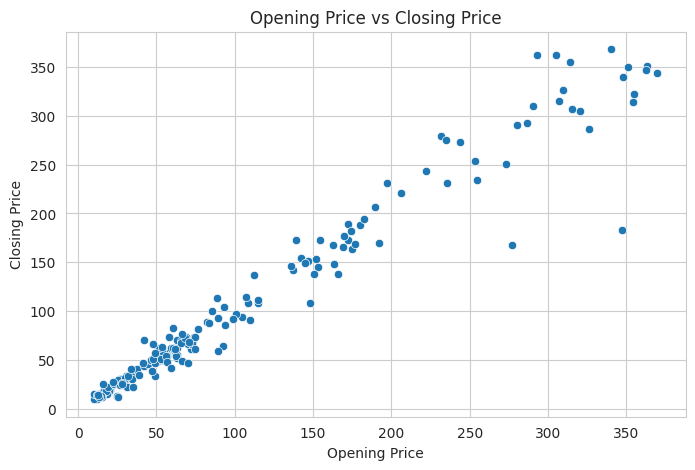

In [25]:
# Chart 15: Opening Price vs Closing Price

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Open', y='Close')

plt.title('Opening Price vs Closing Price')
plt.xlabel('Opening Price')
plt.ylabel('Closing Price')

plt.show()

**Purpose:** To examine the relationship between monthly opening prices and closing prices.

**Observation:** The scatter plot shows a strong positive relationship between opening and closing prices. Higher opening prices generally correspond to higher closing prices.

**Business Impact:** Opening prices contain useful information about closing price levels and can help explain historical stock price movements.

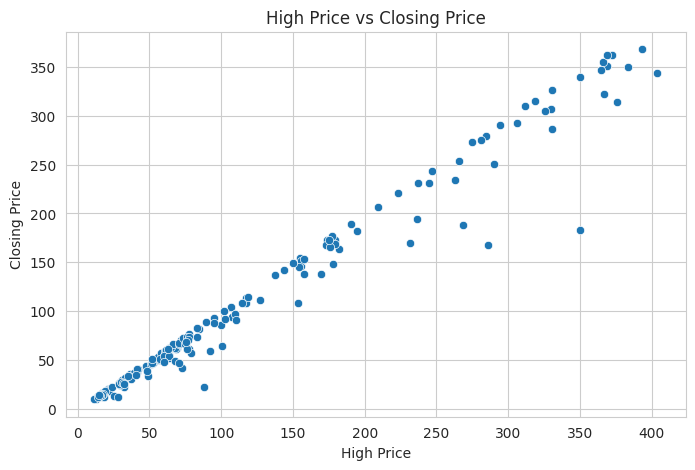

In [26]:
# Chart 16: High Price vs Closing Price

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='High', y='Close')

plt.title('High Price vs Closing Price')
plt.xlabel('High Price')
plt.ylabel('Closing Price')

plt.show()

**Purpose:** To analyse the relationship between monthly high prices and closing prices.

**Observation:** The scatter plot indicates a strong positive relationship, showing that higher monthly high prices are generally associated with higher closing prices.

**Business Impact:** Monthly high prices provide useful information about the stock's price range and can support the analysis of closing price behaviour.

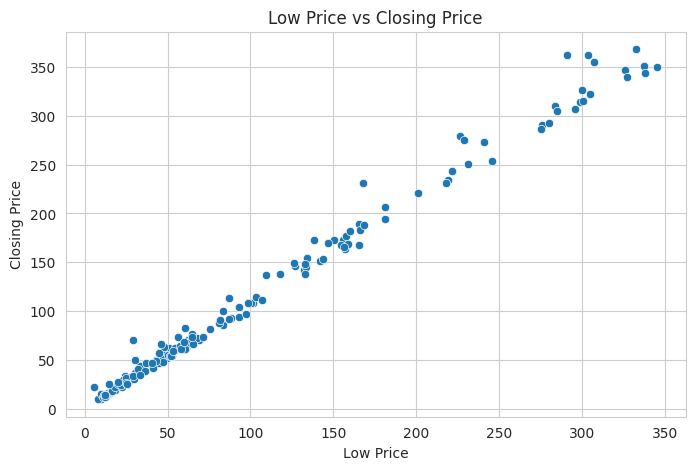

In [27]:
# Chart 17: Low Price vs Closing Price

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Low', y='Close')

plt.title('Low Price vs Closing Price')
plt.xlabel('Low Price')
plt.ylabel('Closing Price')

plt.show()

**Purpose:** To examine the relationship between monthly low prices and closing prices.

**Observation:** The scatter plot shows a positive relationship between low prices and closing prices, indicating that both variables generally move in the same direction.

**Business Impact:** Monthly low prices help capture downside price movements and provide additional information for understanding closing price variations.

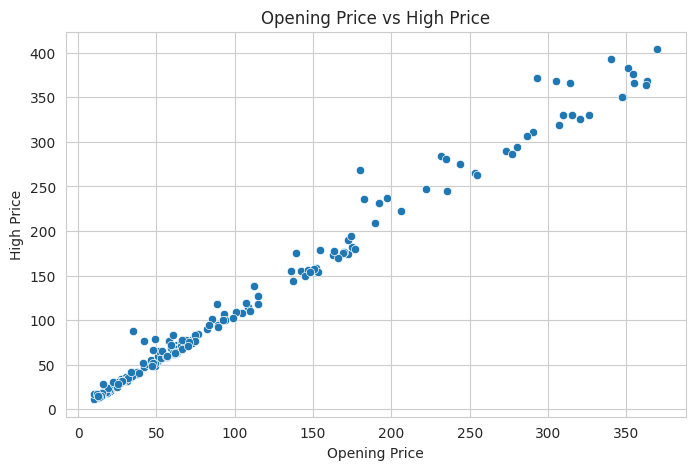

In [28]:
# Chart 18: Opening Price vs High Price

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Open', y='High')

plt.title('Opening Price vs High Price')
plt.xlabel('Opening Price')
plt.ylabel('High Price')

plt.show()

**Purpose:** To understand the relationship between opening prices and monthly high prices.

**Observation:** The scatter plot shows a strong positive association, indicating that higher opening prices generally correspond to higher monthly high prices.

**Business Impact:** This relationship helps understand how monthly upper price levels vary with opening prices and supports the analysis of stock price movements.

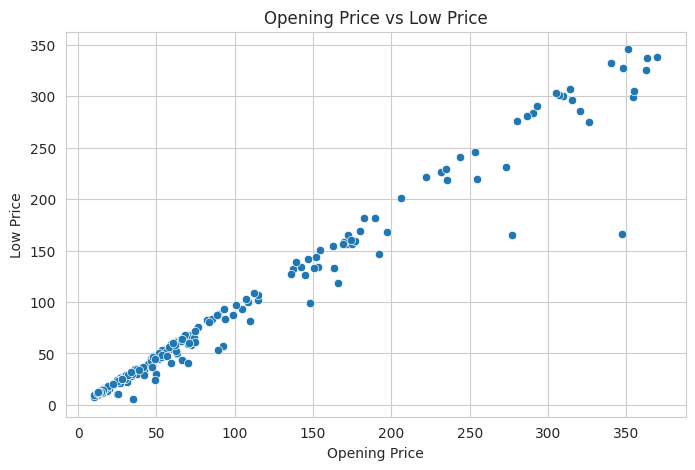

In [29]:
# Chart 19: Opening Price vs Low Price

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Open', y='Low')

plt.title('Opening Price vs Low Price')
plt.xlabel('Opening Price')
plt.ylabel('Low Price')

plt.show()

**Purpose:** To analyse the relationship between monthly opening prices and low prices.

**Observation:** The scatter plot shows a positive association between the two variables, suggesting that lower opening price levels generally correspond to lower monthly low prices.

**Business Impact:** This relationship provides information about monthly downside price movements and helps understand the variation in stock prices.

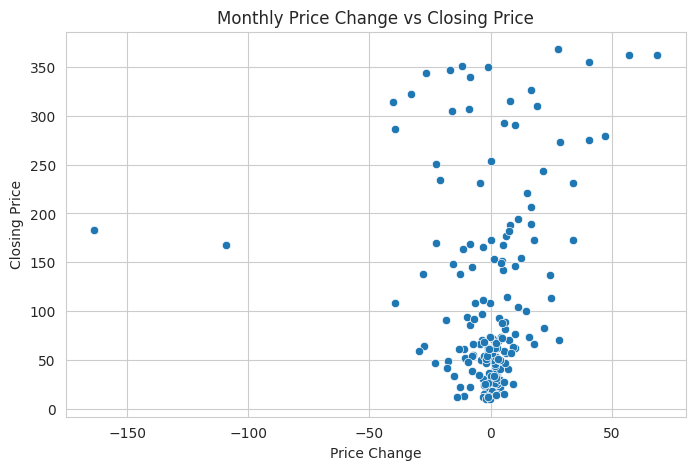

In [30]:
# Chart 20: Price Change vs Closing Price

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Price_Change', y='Close')

plt.title('Monthly Price Change vs Closing Price')
plt.xlabel('Price Change')
plt.ylabel('Closing Price')

plt.show()

**Purpose:** To examine the relationship between the difference between closing and opening prices and the final closing price.

**Observation:** The scatter plot shows how monthly price changes are distributed across different closing price levels. The observations indicate variation in monthly price movements.

**Business Impact:** Analysing price changes helps understand monthly gains and losses and provides additional information about stock price behaviour.

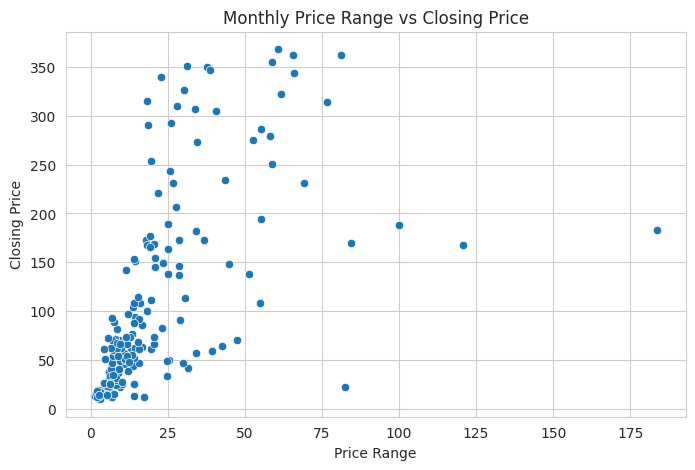

In [31]:
# Chart 21: Price Range vs Closing Price

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Price_Range', y='Close')

plt.title('Monthly Price Range vs Closing Price')
plt.xlabel('Price Range')
plt.ylabel('Closing Price')

plt.show()

**Purpose:** To examine the relationship between the monthly price range (High − Low) and closing price.

**Observation:** The scatter plot illustrates how the difference between monthly high and low prices varies across different closing price levels. Wider ranges indicate greater price movement within a month.

**Business Impact:** Monthly price range helps identify periods of larger price fluctuations and provides an additional measure of stock price variability.

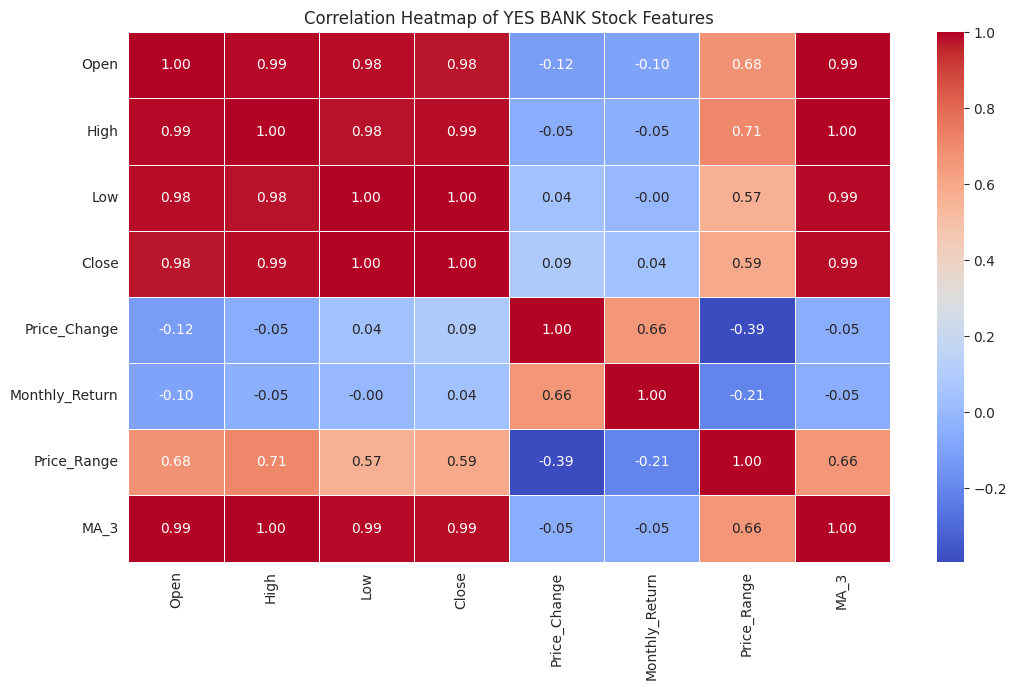

In [32]:
# Chart 22: Correlation Heatmap

plt.figure(figsize=(11, 7))

correlation = df[
    ['Open', 'High', 'Low', 'Close',
     'Price_Change', 'Monthly_Return', 'Price_Range', 'MA_3']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of YES BANK Stock Features')
plt.tight_layout()

plt.show()

**Purpose:** To examine the strength and direction of relationships among OHLC prices and engineered numerical features.

**Observation:** The heatmap displays correlation values between variables. The OHLC price variables show strong positive relationships, while engineered features show different levels of association with the original price variables.

**Business Impact:** Correlation analysis helps identify relationships among features, understand possible redundancy and support informed feature selection during machine learning model development.

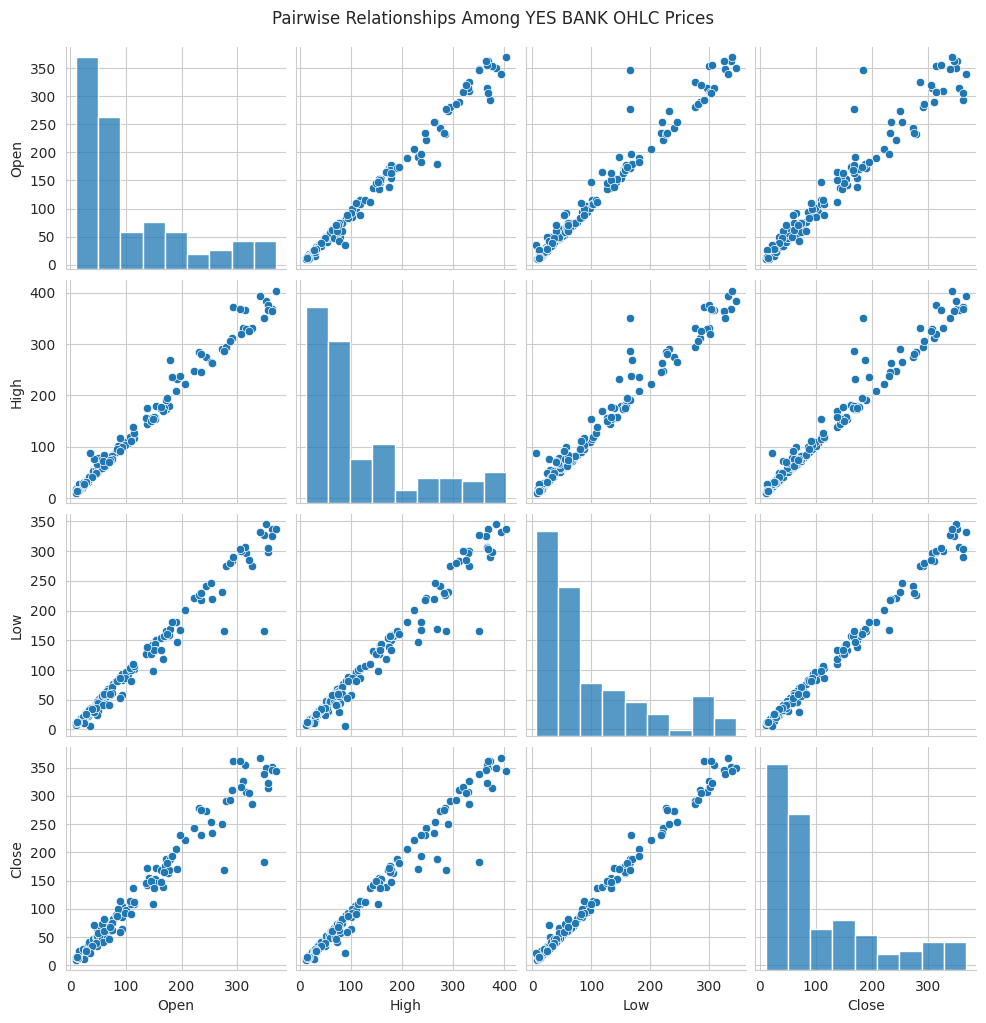

In [33]:
# Chart 23: Pair Plot of OHLC Variables

sns.pairplot(
    df[['Open', 'High', 'Low', 'Close']],
    diag_kind='hist'
)

plt.suptitle(
    'Pairwise Relationships Among YES BANK OHLC Prices',
    y=1.02
)

plt.show()

**Purpose:** To visualise pairwise relationships and individual distributions of opening, high, low and closing prices.

**Observation:** The pair plot shows positive relationships among the OHLC variables. The diagonal histograms display the individual distributions, while the scatter plots reveal how the variables move in relation to one another.

**Business Impact:** This combined analysis provides an overall understanding of relationships among stock price variables and helps identify useful features for the prediction stage.

# Hypothesis Testing

Hypothesis testing is a statistical method used to evaluate assumptions about a dataset using sample data. It helps determine whether observed patterns or relationships are statistically significant.

In this project, hypothesis testing is used to examine monthly stock returns, the relationship between opening and closing prices, and changes in returns across different periods.

In [34]:

# Import statistical testing functions
from scipy.stats import ttest_1samp, pearsonr, ttest_ind

# ==========================================
# Hypothesis Test 1: Average Monthly Return
# ==========================================

returns = df['Monthly_Return'].dropna()

# H0: Average monthly return is equal to zero
# H1: Average monthly return is not equal to zero

test1_stat, test1_p = ttest_1samp(returns, popmean=0)

print("HYPOTHESIS TEST 1: Average Monthly Return")
print("Test Statistic:", round(test1_stat, 4))
print("P-value:", round(test1_p, 4))

if test1_p < 0.05:
    print("Result: Reject the Null Hypothesis.")
    print("Average monthly return is significantly different from zero.")
else:
    print("Result: Fail to Reject the Null Hypothesis.")
    print("No significant difference from zero was found.")


# ==========================================
# Hypothesis Test 2: Open and Close Correlation
# ==========================================

# H0: Open and Close prices have no significant correlation
# H1: Open and Close prices have a significant correlation

correlation, test2_p = pearsonr(df['Open'], df['Close'])

print("\nHYPOTHESIS TEST 2: Open vs Close Correlation")
print("Correlation:", round(correlation, 4))
print("P-value:", round(test2_p, 4))

if test2_p < 0.05:
    print("Result: Reject the Null Hypothesis.")
    print("Open and Close prices have a significant relationship.")
else:
    print("Result: Fail to Reject the Null Hypothesis.")
    print("No significant relationship was found.")


# ==========================================
# Hypothesis Test 3: Early vs Later Period Returns
# ==========================================

# Divide the dataset into two chronological halves
mid_date = df['Date'].median()

early_returns = df.loc[
    df['Date'] <= mid_date, 'Monthly_Return'
].dropna()

later_returns = df.loc[
    df['Date'] > mid_date, 'Monthly_Return'
].dropna()

# H0: Average returns in both periods are equal
# H1: Average returns in both periods are different

test3_stat, test3_p = ttest_ind(
    early_returns,
    later_returns,
    equal_var=False
)

print("\nHYPOTHESIS TEST 3: Early vs Later Period Returns")
print("Early Period Average Return:",
      round(early_returns.mean(), 4))
print("Later Period Average Return:",
      round(later_returns.mean(), 4))
print("P-value:", round(test3_p, 4))

if test3_p < 0.05:
    print("Result: Reject the Null Hypothesis.")
    print("The average returns differ significantly between periods.")
else:
    print("Result: Fail to Reject the Null Hypothesis.")
    print("No significant difference in average returns was found.")


HYPOTHESIS TEST 1: Average Monthly Return
Test Statistic: 1.2281
P-value: 0.221
Result: Fail to Reject the Null Hypothesis.
No significant difference from zero was found.

HYPOTHESIS TEST 2: Open vs Close Correlation
Correlation: 0.978
P-value: 0.0
Result: Reject the Null Hypothesis.
Open and Close prices have a significant relationship.

HYPOTHESIS TEST 3: Early vs Later Period Returns
Early Period Average Return: 3.151
Later Period Average Return: -0.157
P-value: 0.1756
Result: Fail to Reject the Null Hypothesis.
No significant difference in average returns was found.


### Interpretation of Hypothesis Tests

**Test 1 – Average Monthly Return:** This test checks whether YES BANK's average monthly return is statistically different from zero. Since the p-value is greater than 0.05, we fail to reject the null hypothesis. There is insufficient statistical evidence to conclude that the average monthly return is significantly different from zero.

**Test 2 – Opening and Closing Price Relationship:** This test checks whether opening prices and closing prices have a statistically significant relationship. Since the p-value is less than 0.05, we reject the null hypothesis. The results indicate a statistically significant positive relationship between opening and closing prices.

**Test 3 – Early and Later Period Returns:** This test compares the average monthly returns of the first and second halves of the dataset. Since the p-value is greater than 0.05, we fail to reject the null hypothesis. There is insufficient statistical evidence to conclude that the average returns of the two periods are significantly different.

A p-value less than 0.05 indicates statistically significant evidence against the null hypothesis. A p-value greater than or equal to 0.05 means there is insufficient evidence to reject the null hypothesis.

### Limitations of Hypothesis Testing

The hypothesis tests provide useful statistical insights into YES BANK's stock data. However, stock returns may exhibit time dependence and volatility, which can affect the assumptions of traditional statistical tests. The results should therefore be interpreted cautiously and considered as supporting analysis rather than definitive evidence of market behaviour.

## Key Business Insights

This section summarizes the important findings obtained from the exploratory data analysis of YES BANK's historical stock prices. It focuses on price movements, market fluctuations, monthly returns and volatility.

In [35]:
# Key Business Insights

print("YES BANK STOCK PRICE - KEY FINDINGS")
print("=" * 50)

# Closing price statistics
print("\n1. Closing Price Analysis")
print("Average Closing Price:", round(df['Close'].mean(), 2))
print("Maximum Closing Price:", round(df['Close'].max(), 2))
print("Minimum Closing Price:", round(df['Close'].min(), 2))

# Dates of maximum and minimum closing prices
max_date = df.loc[df['Close'].idxmax(), 'Date']
min_date = df.loc[df['Close'].idxmin(), 'Date']

print("Date of Maximum Closing Price:", max_date.strftime('%b-%Y'))
print("Date of Minimum Closing Price:", min_date.strftime('%b-%Y'))

# Monthly return analysis
print("\n2. Monthly Return Analysis")
print("Average Monthly Return (%):",
      round(df['Monthly_Return'].mean(), 2))

print("Highest Monthly Return (%):",
      round(df['Monthly_Return'].max(), 2))

print("Lowest Monthly Return (%):",
      round(df['Monthly_Return'].min(), 2))

# Positive and negative return months
positive_months = (df['Monthly_Return'] > 0).sum()
negative_months = (df['Monthly_Return'] < 0).sum()

print("\n3. Return Frequency")
print("Positive Return Months:", positive_months)
print("Negative Return Months:", negative_months)

# Price range analysis
print("\n4. Price Range Analysis")
print("Average Monthly Price Range:",
      round(df['Price_Range'].mean(), 2))

print("\n5. Volatility Analysis")
print("Standard Deviation of Monthly Returns (%):",
      round(df['Monthly_Return'].std(), 2))

YES BANK STOCK PRICE - KEY FINDINGS

1. Closing Price Analysis
Average Closing Price: 105.2
Maximum Closing Price: 367.9
Minimum Closing Price: 9.98
Date of Maximum Closing Price: Jul-2018
Date of Minimum Closing Price: Mar-2009

2. Monthly Return Analysis
Average Monthly Return (%): 1.5
Highest Monthly Return (%): 69.96
Lowest Monthly Return (%): -53.32

3. Return Frequency
Positive Return Months: 101
Negative Return Months: 83

4. Price Range Analysis
Average Monthly Price Range: 21.16

5. Volatility Analysis
Standard Deviation of Monthly Returns (%): 16.53


### Key Business Insights

1. **Closing Price Trend:** YES BANK recorded an average closing price of ₹105.20, with a maximum of ₹367.90 in July 2018 and a minimum of ₹9.98 in March 2009.

2. **Monthly Returns:** The average monthly return was 1.50%. However, the highest return was 69.96%, while the lowest was -53.32%, indicating substantial fluctuations in monthly performance.

3. **Return Frequency:** The stock recorded 101 positive-return months and 83 negative-return months, showing that positive monthly movements were slightly more frequent during the observed period.
Monthly returns were available for 184 observations because the first month's return could not be calculated without a previous month's closing price.

4. **Price Fluctuation:** The average difference between the monthly high and low prices was ₹21.16, indicating considerable variation within individual months.

5. **Market Volatility:** The standard deviation of monthly returns was 16.53%, highlighting the uncertainty and risk associated with the stock's historical price movements.

6. **Overall Observation:** The historical data shows that YES BANK experienced significant price fluctuations. Although positive-return months were more frequent, the large positive and negative monthly movements indicate that the stock's performance was not consistent.

## EDA Conclusion

The Exploratory Data Analysis of YES BANK stock prices helped identify historical price trends, monthly returns, price fluctuations and volatility from July 2005 to November 2020.

The analysis revealed considerable variations in stock prices, including significant increases and declines. The distribution of prices and monthly returns also highlighted the presence of extreme movements.

The findings provide a better understanding of YES BANK's historical stock behaviour and help identify relevant patterns for further analysis.

These insights will be used in the next phase to develop and evaluate Machine Learning models for predicting the next month's closing price.